In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneOut
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
df = pd.read_csv('moisture.csv')

In [3]:
X = df.iloc[:,:-1].values
y = df.iloc[:,-1].values

loo = LeaveOneOut()

Regressão Linear
MAE: 0.22758066684502698
MSE: 0.10098034198610682
R²: 0.517284876690711


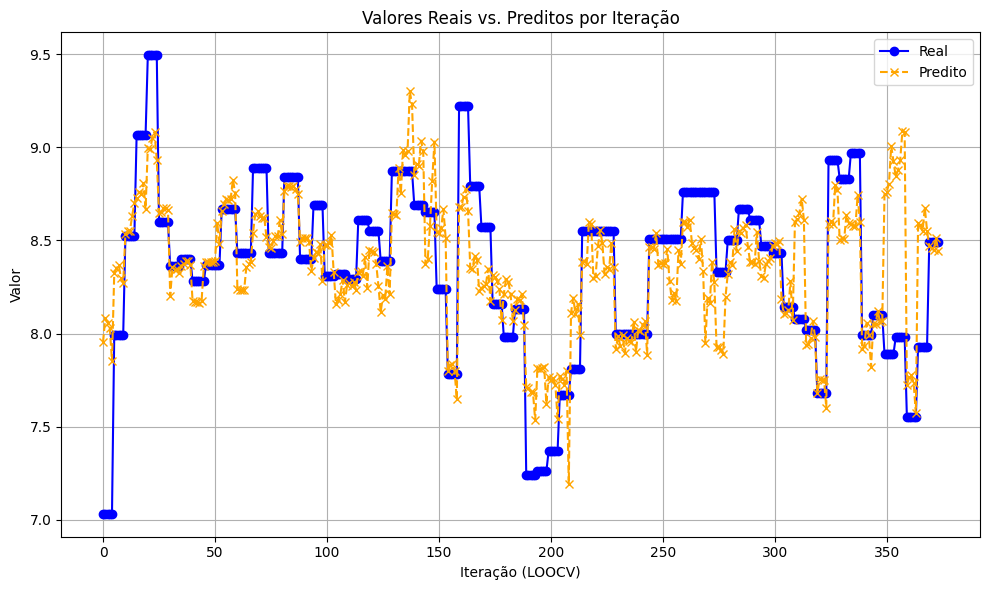

In [4]:
import matplotlib.pyplot as plt

y_true, y_pred = [], []

for train_index, test_index in loo.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred.append(model.predict(X_test)[0])
    y_true.append(y_test[0])

print("Regressão Linear")
print("MAE:", mean_absolute_error(y_true, y_pred))
print("MSE:", mean_squared_error(y_true, y_pred))
print("R²:", r2_score(y_true, y_pred))

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(y_true)), y_true, label='Real', marker='o', linestyle='-', color='blue')
plt.plot(range(len(y_pred)), y_pred, label='Predito', marker='x', linestyle='--', color='orange')
plt.xlabel("Iteração (LOOCV)")
plt.ylabel("Valor")
plt.title("Valores Reais vs. Preditos por Iteração")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [23]:
final_model = LinearRegression()
final_model.fit(X, y)

coef = final_model.coef_
intercept = final_model.intercept_

# Construir string da equação
equation = "y = " + " + ".join(f"{c:.4f}*{name}" for c, name in zip(coef, df.columns[:-1]))
equation += f" + {intercept:.4f}"

print("Equação da Regressão Linear:")
print(equation)

Equação da Regressão Linear:
y = -0.0624*Torque (Nm) + -0.0149*Altura (mm) + 0.0003*Densidade (g/cm3) + 0.0272*Condutividade (uS/cm) + -0.0092*Permissividade + 7.7998


Random Forest (5 árvores)
MAE: 0.17502513368983963
MSE: 0.06665361037433155
R²: 0.6813765420275417


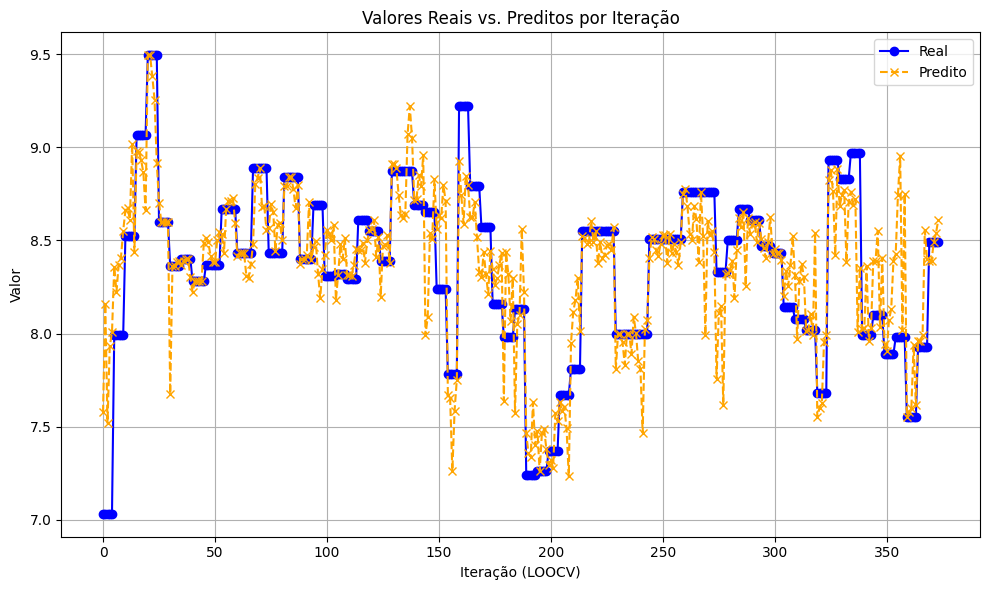

In [17]:

y_true, y_pred = [], []

for train_index, test_index in loo.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = RandomForestRegressor(n_estimators=5, random_state=42)
    model.fit(X_train, y_train)
    y_pred.append(model.predict(X_test)[0])
    y_true.append(y_test[0])

print("Random Forest (5 árvores)")
print("MAE:", mean_absolute_error(y_true, y_pred))
print("MSE:", mean_squared_error(y_true, y_pred))
print("R²:", r2_score(y_true, y_pred))

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(y_true)), y_true, label='Real', marker='o', linestyle='-', color='blue')
plt.plot(range(len(y_pred)), y_pred, label='Predito', marker='x', linestyle='--', color='orange')
plt.xlabel("Iteração (LOOCV)")
plt.ylabel("Valor")
plt.title("Valores Reais vs. Preditos por Iteração")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



Árvore de Decisão
MAE: 0.17748930481283423
MSE: 0.09742877807486632
R²: 0.5342623752576217


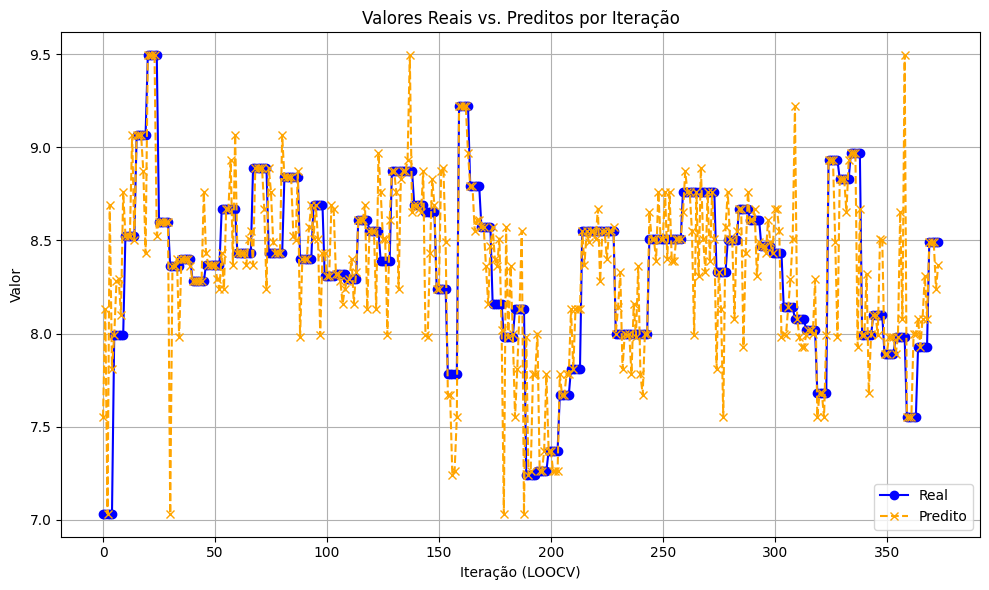

In [5]:
y_true, y_pred = [], []

for train_index, test_index in loo.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = DecisionTreeRegressor()
    model.fit(X_train, y_train)
    y_pred.append(model.predict(X_test)[0])
    y_true.append(y_test[0])

print("Árvore de Decisão")
print("MAE:", mean_absolute_error(y_true, y_pred))
print("MSE:", mean_squared_error(y_true, y_pred))
print("R²:", r2_score(y_true, y_pred))

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(y_true)), y_true, label='Real', marker='o', linestyle='-', color='blue')
plt.plot(range(len(y_pred)), y_pred, label='Predito', marker='x', linestyle='--', color='orange')
plt.xlabel("Iteração (LOOCV)")
plt.ylabel("Valor")
plt.title("Valores Reais vs. Preditos por Iteração")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



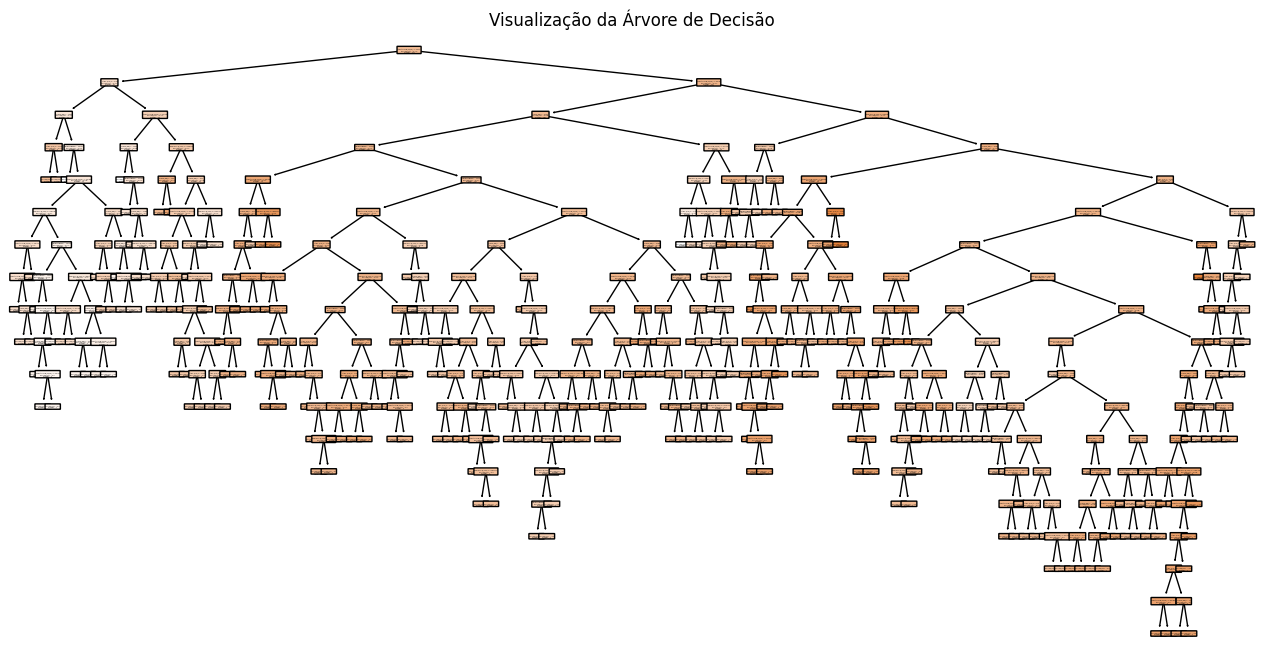

In [21]:
from sklearn.tree import plot_tree

# Treinar uma árvore com todos os dados apenas para visualização
tree_model = DecisionTreeRegressor()
tree_model.fit(X, y)

plt.figure(figsize=(16, 8))
plot_tree(tree_model, filled=True, feature_names=df.columns[:-1], rounded=True)
plt.title("Visualização da Árvore de Decisão")
plt.show()


Random Forest (15 árvores)
MAE: 0.1624837789661318
MSE: 0.0563562637433155
R²: 0.7306008251997387


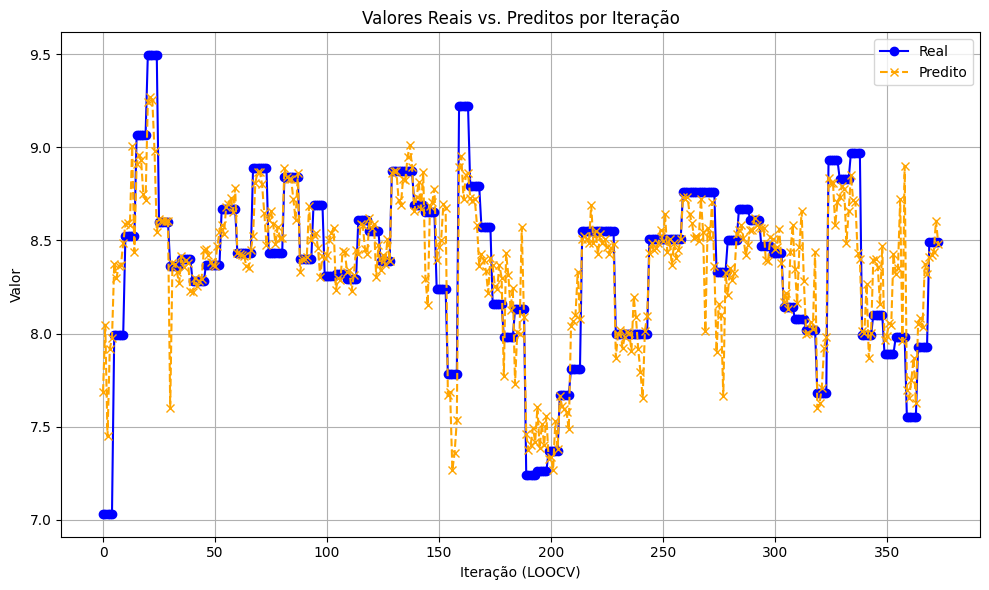

In [25]:

y_true, y_pred = [], []

for train_index, test_index in loo.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = RandomForestRegressor(n_estimators=15, random_state=42)
    model.fit(X_train, y_train)
    y_pred.append(model.predict(X_test)[0])
    y_true.append(y_test[0])

print("Random Forest (15 árvores)")
print("MAE:", mean_absolute_error(y_true, y_pred))
print("MSE:", mean_squared_error(y_true, y_pred))
print("R²:", r2_score(y_true, y_pred))

plt.figure(figsize=(10, 6))
plt.plot(range(len(y_true)), y_true, label='Real', marker='o', linestyle='-', color='blue')
plt.plot(range(len(y_pred)), y_pred, label='Predito', marker='x', linestyle='--', color='orange')
plt.xlabel("Iteração (LOOCV)")
plt.ylabel("Valor")
plt.title("Valores Reais vs. Preditos por Iteração")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:
!pip install micromlgen


  Preparing metadata (setup.py) ... done
  Created wheel for micromlgen: filename=micromlgen-1.1.28-py3-none-any.whl size=32152 sha256=b75f1fa2b5eb234772c7e084ba670a5530a4082741d7466256ce1ddd611ac4ea
  Stored in directory: /root/.cache/pip/wheels/aa/3a/19/9fd4635f110202e18f3b4bb631e90287ba06eb406999726cb9
Successfully built micromlgen


In [8]:
from micromlgen import port
import numpy as np
# Train a Random Forest model
model = RandomForestRegressor(n_estimators=15, random_state=0)
model.fit(X, y)

# Generate C code
c_code = port(model)

# Save the generated C code to a file
with open("random_forest15_model.c", "w") as f:
    f.write(c_code)

print("Model has been converted to C code and saved as 'random_forest15_model.c'.")

Model has been converted to C code and saved as 'random_forest15_model.c'.


In [7]:
from micromlgen import port
import numpy as np
# Train a Random Forest model
model = DecisionTreeRegressor()
model.fit(X_train, y_train)

# Generate C code
c_code = port(model)

# Save the generated C code to a file
with open("DT_model.c", "w") as f:
    f.write(c_code)

print("Model has been converted to C code and saved as 'DT_model.c'.")

Model has been converted to C code and saved as 'DT_model.c'.
